# Лабораторная работа №6. Отбор признаков и снижение размерности

**Цель работы:** исследовать методы отбора признаков (*Feature Selection*) и снижения размерности (*Dimensionality Reduction*) в задачах классификации (`csv/cl_finished.csv`) и регрессии (`csv/winequality_finished.csv`), сравнить качество моделей до и после сжатия признакового пространства, а также реализовать метод главных компонент (`CustomPCA`) с нуля и визуализировать кластеризацию `MyKMeans` в пространстве первых двух главных компонент.

### Исследуемые методы
1. **Отбор признаков (Feature Selection):**
   * `VarianceThreshold` — фильтрация низковариативных признаков по порогу дисперсии;
   * `SelectKBest` — одномерный статистический отбор лучших $k$ признаков по $F$-критерию (`f_classif` / `f_regression`);
   * `RFE` (*Recursive Feature Elimination*) — рекурсивное исключение наименее значимых признаков на основе весов/важностей базовой модели.
2. **Линейное и нелинейное снижение размерности (Dimensionality Reduction):**
   * `PCA` (*Principal Component Analysis*) — ортогональная линейная проекция на направления максимальной дисперсии;
   * `KernelPCA` (`poly`, `rbf`, `sigmoid`) — ядерное обобщение метода главных компонент;
   * `t-SNE` — стохастическое вложение соседей с $t$-распределением (сохранение локальной структуры);
   * `Isomap` — изометрическое отображение на основе геодезических расстояний по графу ближайших соседей;
   * `UMAP` — аппроксимация и проекция равномерного многообразия.
3. **Собственная реализация `CustomPCA` + кластеризация `MyKMeans`.**

## 1. Импорт библиотек и вспомогательные функции оценки

In [1]:
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import umap

from sklearn.tree import DecisionTreeClassifier, DecisionTreeRegressor
from sklearn.ensemble import BaggingClassifier, BaggingRegressor
from sklearn.model_selection import train_test_split
from sklearn.metrics import (classification_report, accuracy_score, f1_score,
                             r2_score, mean_absolute_error)
from sklearn.preprocessing import StandardScaler
from sklearn.feature_selection import VarianceThreshold, SelectKBest, f_classif, f_regression, RFE
from sklearn.decomposition import PCA, KernelPCA
from sklearn.manifold import TSNE, Isomap

sns.set_theme(style='whitegrid')
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

In [2]:
cl_results = {}
reg_results = {}


def test_classification(X, y, label='Исходные данные'):
    X_train, X_test, y_train, y_test = train_test_split(
        X, y, test_size=0.15, stratify=y, random_state=RANDOM_STATE
    )
    bag = BaggingClassifier(random_state=RANDOM_STATE, n_jobs=-1).fit(X_train, y_train)
    preds = bag.predict(X_test)
    acc = accuracy_score(y_test, preds)
    f1_w = f1_score(y_test, preds, average='weighted', zero_division=0)
    f1_m = f1_score(y_test, preds, average='macro', zero_division=0)
    cl_results[label] = {'Число признаков': X.shape[1], 'Accuracy': acc, 'F1 (weighted)': f1_w, 'F1 (macro)': f1_m}
    print(f'=== Классификация: {label} (признаков: {X.shape[1]}) ===')
    print(classification_report(y_test, preds, zero_division=0))


def test_regression(X, y, label='Исходные данные'):
    X_train, X_test, y_train, y_test = train_test_split(
        X, y, test_size=0.15, random_state=RANDOM_STATE
    )
    bag = BaggingRegressor(random_state=RANDOM_STATE, n_jobs=-1).fit(X_train, y_train)
    preds = bag.predict(X_test)
    r2 = r2_score(y_test, preds)
    mae = mean_absolute_error(y_test, preds)
    reg_results[label] = {'Число признаков': X.shape[1], 'R2': r2, 'MAE': mae}
    print(f'Регрессия [{label}] (признаков: {X.shape[1]}) -> R2 Score: {r2:.4f} | MAE: {mae:.4f}')

## 2. Загрузка и масштабирование данных

In [3]:
df_class = pd.read_csv('csv/cl_finished.csv', sep=';')
X_cl = df_class.drop(columns='Diabetes_012')
y_cl = df_class['Diabetes_012']

df_reg = pd.read_csv('csv/winequality_finished.csv', sep=';')
X_reg = df_reg.drop(columns='quality')
y_reg = df_reg['quality']

scaler_cl = StandardScaler()
X_cl_scaled = pd.DataFrame(scaler_cl.fit_transform(X_cl), columns=X_cl.columns)

scaler_reg = StandardScaler()
X_reg_scaled = pd.DataFrame(scaler_reg.fit_transform(X_reg), columns=X_reg.columns)

# Стратифицированные подвыборки для алгоритмов с квадратичной сложностью по числу объектов (KernelPCA, Isomap, t-SNE, UMAP)
X_cl_sampled, _, y_cl_sampled, _ = train_test_split(X_cl_scaled, y_cl, train_size=6000, stratify=y_cl, random_state=RANDOM_STATE)
X_cl_sampled, y_cl_sampled = X_cl_sampled.reset_index(drop=True), y_cl_sampled.reset_index(drop=True)
X_cl_sampled_tsne, _, y_cl_sampled_tsne, _ = train_test_split(X_cl_scaled, y_cl, train_size=3000, stratify=y_cl, random_state=RANDOM_STATE)
X_cl_sampled_tsne, y_cl_sampled_tsne = X_cl_sampled_tsne.reset_index(drop=True), y_cl_sampled_tsne.reset_index(drop=True)

print(f'Классификация: {X_cl.shape}, Регрессия: {X_reg.shape}')

Классификация: (229781, 21), Регрессия: (6497, 12)


# Часть 1. Отбор признаков и снижение размерности для задачи классификации

## 1.1. Базовое качество на всех 21 признаках

In [4]:
test_classification(X_cl, y_cl, 'Исходные данные (21)')

=== Классификация: Исходные данные (21) (признаков: 21) ===
              precision    recall  f1-score   support

           0       0.85      0.94      0.89     28509
           1       0.01      0.00      0.00       694
           2       0.38      0.21      0.27      5265

    accuracy                           0.81     34468
   macro avg       0.41      0.38      0.39     34468
weighted avg       0.76      0.81      0.78     34468



## 1.2. VarianceThreshold

In [5]:
display(X_cl.var().rename('Дисперсия').to_frame().T.round(4))

cl_vt = VarianceThreshold(threshold=0.05)
X_cl_vt = pd.DataFrame(cl_vt.fit_transform(X_cl), columns=cl_vt.get_feature_names_out())
print(f'[VarianceThreshold] Отобрано {X_cl_vt.shape[1]} признаков: {list(X_cl_vt.columns)}')
test_classification(X_cl_vt, y_cl, 'VarianceThreshold')

,HighBP,HighChol,CholCheck,BMI,Smoker,Stroke,HeartDiseaseorAttack,PhysActivity,Fruits,Veggies,...,AnyHealthcare,NoDocbcCost,GenHlth,MentHlth,PhysHlth,DiffWalk,Sex,Age,Education,Income
Дисперсия,0.2479,0.2466,0.0388,46.0547,0.2488,0.0428,0.0926,0.1955,0.2372,0.1631,...,0.051,0.0842,1.1336,59.5016,81.8404,0.1511,0.2463,9.5717,0.9858,4.3785


[VarianceThreshold] Отобрано 19 признаков: ['HighBP', 'HighChol', 'BMI', 'Smoker', 'HeartDiseaseorAttack', 'PhysActivity', 'Fruits', 'Veggies', 'HvyAlcoholConsump', 'AnyHealthcare', 'NoDocbcCost', 'GenHlth', 'MentHlth', 'PhysHlth', 'DiffWalk', 'Sex', 'Age', 'Education', 'Income']
=== Классификация: VarianceThreshold (признаков: 19) ===
              precision    recall  f1-score   support

           0       0.85      0.94      0.89     28509
           1       0.03      0.00      0.01       694
           2       0.39      0.22      0.28      5265

    accuracy                           0.81     34468
   macro avg       0.42      0.39      0.39     34468
weighted avg       0.76      0.81      0.78     34468



## 1.3. SelectKBest (`f_classif`)

In [6]:
skb_cl = SelectKBest(score_func=f_classif, k=12)
X_cl_skb = pd.DataFrame(skb_cl.fit_transform(X_cl, y_cl), columns=skb_cl.get_feature_names_out())
print(f'[SelectKBest] Отобранные признаки: {list(X_cl_skb.columns)}')
test_classification(X_cl_skb, y_cl, 'SelectKBest (k=12)')

[SelectKBest] Отобранные признаки: ['HighBP', 'HighChol', 'BMI', 'Stroke', 'HeartDiseaseorAttack', 'PhysActivity', 'GenHlth', 'PhysHlth', 'DiffWalk', 'Age', 'Education', 'Income']
=== Классификация: SelectKBest (k=12) (признаков: 12) ===
              precision    recall  f1-score   support

           0       0.85      0.92      0.89     28509
           1       0.02      0.00      0.01       694
           2       0.37      0.23      0.29      5265

    accuracy                           0.80     34468
   macro avg       0.41      0.39      0.39     34468
weighted avg       0.76      0.80      0.78     34468



## 1.4. Рекурсивный отбор признаков (RFE)

In [7]:
rfe_cl = RFE(estimator=DecisionTreeClassifier(max_depth=10, random_state=RANDOM_STATE),
             n_features_to_select=12, step=2).fit(X_cl, y_cl)
X_cl_rfe = pd.DataFrame(rfe_cl.transform(X_cl), columns=rfe_cl.get_feature_names_out())
print(f'[RFE] Отобранные признаки: {list(X_cl_rfe.columns)}')
test_classification(X_cl_rfe, y_cl, 'RFE (k=12)')

[RFE] Отобранные признаки: ['HighBP', 'HighChol', 'BMI', 'HeartDiseaseorAttack', 'HvyAlcoholConsump', 'GenHlth', 'MentHlth', 'PhysHlth', 'Sex', 'Age', 'Education', 'Income']
=== Классификация: RFE (k=12) (признаков: 12) ===
              precision    recall  f1-score   support

           0       0.85      0.93      0.89     28509
           1       0.04      0.01      0.02       694
           2       0.38      0.24      0.29      5265

    accuracy                           0.80     34468
   macro avg       0.42      0.39      0.40     34468
weighted avg       0.76      0.80      0.78     34468



## 1.5. Метод главных компонент (PCA)

In [8]:
pca_cl = PCA(n_components=12, random_state=RANDOM_STATE)
X_cl_pca = pca_cl.fit_transform(X_cl_scaled)
print(f'Доля объяснённой дисперсии 12 компонентами: {pca_cl.explained_variance_ratio_.sum():.2%}')
test_classification(X_cl_pca, y_cl, 'PCA (12)')

Доля объяснённой дисперсии 12 компонентами: 73.11%
=== Классификация: PCA (12) (признаков: 12) ===
              precision    recall  f1-score   support

           0       0.85      0.95      0.90     28509
           1       0.03      0.00      0.01       694
           2       0.40      0.19      0.25      5265

    accuracy                           0.81     34468
   macro avg       0.43      0.38      0.38     34468
weighted avg       0.76      0.81      0.78     34468



## 1.6. Ядерный PCA — KernelPCA (`poly`, `rbf`, `sigmoid`)

In [9]:
for kernel in ['poly', 'rbf', 'sigmoid']:
    kpca_cl = KernelPCA(n_components=5, kernel=kernel, n_jobs=-1, random_state=RANDOM_STATE)
    X_cl_kpca = kpca_cl.fit_transform(X_cl_sampled)
    test_classification(X_cl_kpca, y_cl_sampled, f'KernelPCA ({kernel})')

=== Классификация: KernelPCA (poly) (признаков: 5) ===
              precision    recall  f1-score   support

           0       0.82      0.94      0.88       727
           1       0.00      0.00      0.00        18
           2       0.38      0.17      0.24       155

    accuracy                           0.79       900
   macro avg       0.40      0.37      0.37       900
weighted avg       0.73      0.79      0.75       900

=== Классификация: KernelPCA (rbf) (признаков: 5) ===
              precision    recall  f1-score   support

           0       0.83      0.93      0.88       727
           1       0.00      0.00      0.00        18
           2       0.40      0.21      0.28       155

    accuracy                           0.79       900
   macro avg       0.41      0.38      0.39       900
weighted avg       0.74      0.79      0.76       900

=== Классификация: KernelPCA (sigmoid) (признаков: 5) ===
              precision    recall  f1-score   support

           0    

## 1.7. Нелинейные методы многообразий: t-SNE, Isomap, UMAP

In [10]:
tsne_cl = TSNE(n_components=3, random_state=RANDOM_STATE, n_jobs=-1)
X_cl_tsne = tsne_cl.fit_transform(X_cl_sampled_tsne)
test_classification(X_cl_tsne, y_cl_sampled_tsne, 't-SNE (3)')

iso_cl = Isomap(n_components=5, n_neighbors=10, n_jobs=-1)
X_cl_iso = iso_cl.fit_transform(X_cl_sampled)
test_classification(X_cl_iso, y_cl_sampled, 'Isomap (5)')

umap_cl = umap.UMAP(n_components=5, random_state=RANDOM_STATE)
X_cl_umap = umap_cl.fit_transform(X_cl_sampled)
test_classification(X_cl_umap, y_cl_sampled, 'UMAP (5)')

=== Классификация: t-SNE (3) (признаков: 3) ===
              precision    recall  f1-score   support

           0       0.80      0.91      0.85       349
           1       0.00      0.00      0.00         7
           2       0.37      0.21      0.27        94

    accuracy                           0.75       450
   macro avg       0.39      0.37      0.37       450
weighted avg       0.70      0.75      0.72       450

=== Классификация: Isomap (5) (признаков: 5) ===
              precision    recall  f1-score   support

           0       0.82      0.96      0.89       727
           1       0.00      0.00      0.00        18
           2       0.39      0.12      0.19       155

    accuracy                           0.80       900
   macro avg       0.40      0.36      0.36       900
weighted avg       0.73      0.80      0.75       900

=== Классификация: UMAP (5) (признаков: 5) ===
              precision    recall  f1-score   support

           0       0.82      0.92      

# Часть 2. Отбор признаков и снижение размерности для задачи регрессии

## 2.1. Базовое качество и методы отбора признаков (`VarianceThreshold`, `SelectKBest`, `RFE`)

In [11]:
test_regression(X_reg, y_reg, 'Исходные данные (12)')

reg_vt = VarianceThreshold(threshold=0.02)
X_reg_vt = pd.DataFrame(reg_vt.fit_transform(X_reg), columns=reg_vt.get_feature_names_out())
print(f'[VarianceThreshold] Отобранные признаки ({X_reg_vt.shape[1]}): {list(X_reg_vt.columns)}')
test_regression(X_reg_vt, y_reg, 'VarianceThreshold')

skb_reg = SelectKBest(score_func=f_regression, k=7)
X_reg_skb = pd.DataFrame(skb_reg.fit_transform(X_reg, y_reg), columns=skb_reg.get_feature_names_out())
print(f'[SelectKBest] Отобранные признаки (7): {list(X_reg_skb.columns)}')
test_regression(X_reg_skb, y_reg, 'SelectKBest (k=7)')

rfe_reg = RFE(estimator=DecisionTreeRegressor(random_state=RANDOM_STATE), n_features_to_select=7, step=1).fit(X_reg, y_reg)
X_reg_rfe = pd.DataFrame(rfe_reg.transform(X_reg), columns=rfe_reg.get_feature_names_out())
print(f'[RFE] Отобранные признаки (7): {list(X_reg_rfe.columns)}')
test_regression(X_reg_rfe, y_reg, 'RFE (k=7)')

Регрессия [Исходные данные (12)] (признаков: 12) -> R2 Score: 0.4302 | MAE: 0.4607
[VarianceThreshold] Отобранные признаки (10): ['red', 'fixed acidity', 'volatile acidity', 'citric acid', 'residual sugar', 'free sulfur dioxide', 'total sulfur dioxide', 'pH', 'sulphates', 'alcohol']
Регрессия [VarianceThreshold] (признаков: 10) -> R2 Score: 0.4322 | MAE: 0.4613
[SelectKBest] Отобранные признаки (7): ['red', 'fixed acidity', 'volatile acidity', 'citric acid', 'chlorides', 'density', 'alcohol']
Регрессия [SelectKBest (k=7)] (признаков: 7) -> R2 Score: 0.3672 | MAE: 0.4812
[RFE] Отобранные признаки (7): ['volatile acidity', 'residual sugar', 'chlorides', 'free sulfur dioxide', 'total sulfur dioxide', 'sulphates', 'alcohol']
Регрессия [RFE (k=7)] (признаков: 7) -> R2 Score: 0.4214 | MAE: 0.4695


## 2.2. Методы снижения размерности для регрессии (`PCA`, `KernelPCA`, `t-SNE`, `Isomap`, `UMAP`)

In [12]:
pca_reg = PCA(n_components=7, random_state=RANDOM_STATE)
X_reg_pca = pca_reg.fit_transform(X_reg_scaled)
test_regression(X_reg_pca, y_reg, 'PCA (7)')

for kernel in ['poly', 'rbf', 'sigmoid']:
    kpca_reg = KernelPCA(n_components=5, kernel=kernel, n_jobs=-1, random_state=RANDOM_STATE)
    X_reg_kpca = kpca_reg.fit_transform(X_reg_scaled)
    test_regression(X_reg_kpca, y_reg, f'KernelPCA ({kernel})')

tsne_reg = TSNE(n_components=3, random_state=RANDOM_STATE, perplexity=30, n_jobs=-1)
X_reg_tsne = tsne_reg.fit_transform(X_reg_scaled)
test_regression(X_reg_tsne, y_reg, 't-SNE (3)')

iso_reg = Isomap(n_components=5, n_neighbors=15, n_jobs=-1)
X_reg_iso = iso_reg.fit_transform(X_reg_scaled)
test_regression(X_reg_iso, y_reg, 'Isomap (5)')

umap_reg = umap.UMAP(n_components=5, random_state=RANDOM_STATE)
X_reg_umap = umap_reg.fit_transform(X_reg_scaled)
test_regression(X_reg_umap, y_reg, 'UMAP (5)')

Регрессия [PCA (7)] (признаков: 7) -> R2 Score: 0.4479 | MAE: 0.4584
Регрессия [KernelPCA (poly)] (признаков: 5) -> R2 Score: 0.3950 | MAE: 0.4925
Регрессия [KernelPCA (rbf)] (признаков: 5) -> R2 Score: 0.4003 | MAE: 0.4779
Регрессия [KernelPCA (sigmoid)] (признаков: 5) -> R2 Score: 0.4607 | MAE: 0.4586
Регрессия [t-SNE (3)] (признаков: 3) -> R2 Score: 0.4134 | MAE: 0.4693
Регрессия [Isomap (5)] (признаков: 5) -> R2 Score: 0.3560 | MAE: 0.4919
Регрессия [UMAP (5)] (признаков: 5) -> R2 Score: 0.3535 | MAE: 0.5145


## 2.3. Сводное сравнение методов отбора признаков и снижения размерности

=== Сводная таблица: Классификация ===


,Число признаков,Accuracy,F1 (weighted),F1 (macro)
Исходные данные (21),21.0,0.8083,0.7792,0.3881
VarianceThreshold,19.0,0.8083,0.7805,0.3928
SelectKBest (k=12),12.0,0.8006,0.7775,0.3933
RFE (k=12),12.0,0.8032,0.7797,0.3983
PCA (12),12.0,0.8139,0.7796,0.3848
KernelPCA (poly),5.0,0.7867,0.7494,0.3716
KernelPCA (rbf),5.0,0.7867,0.7561,0.3850
KernelPCA (sigmoid),5.0,0.7922,0.7575,0.3813
t-SNE (3),3.0,0.7511,0.7185,0.3747
Isomap (5),5.0,0.7978,0.7482,0.3576


=== Сводная таблица: Регрессия ===


,Число признаков,R2,MAE
KernelPCA (sigmoid),5.0,0.4607,0.4586
PCA (7),7.0,0.4479,0.4584
VarianceThreshold,10.0,0.4322,0.4613
Исходные данные (12),12.0,0.4302,0.4607
RFE (k=7),7.0,0.4214,0.4695
t-SNE (3),3.0,0.4134,0.4693
KernelPCA (rbf),5.0,0.4003,0.4779
KernelPCA (poly),5.0,0.3950,0.4925
SelectKBest (k=7),7.0,0.3672,0.4812
Isomap (5),5.0,0.3560,0.4919


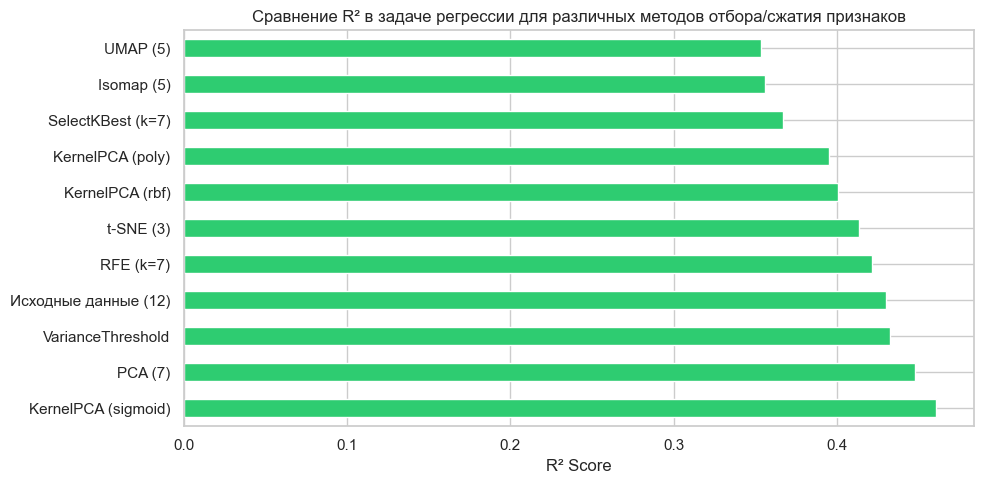

In [13]:
print('=== Сводная таблица: Классификация ===')
display(pd.DataFrame(cl_results).T.round(4))

print('=== Сводная таблица: Регрессия ===')
reg_df = pd.DataFrame(reg_results).T.sort_values('R2', ascending=False)
display(reg_df.round(4))

plt.figure(figsize=(10, 5))
reg_df['R2'].plot(kind='barh', color='#2ecc71')
plt.title('Сравнение R² в задаче регрессии для различных методов отбора/сжатия признаков')
plt.xlabel('R² Score')
plt.tight_layout()
plt.show()

# Часть 3. Собственная реализация PCA (`CustomPCA`) и визуализация кластеризации `MyKMeans`

Математический алгоритм метода главных компонент:
1. Центрирование матрицы признаков: $X_c = X - \bar{X}$;
2. Вычисление выборочной ковариационной матрицы: $\Sigma = \frac{1}{n - 1} X_c^T X_c$;
3. Спектральное разложение симметричной матрицы $\Sigma = V \Lambda V^T$ (`np.linalg.eigh`);
4. Сортировка собственных значений $\lambda_1 \ge \lambda_2 \ge \dots \ge \lambda_d$ и выбор первых $k$ собственных векторов $W_k$;
5. Проекция данных: $Z = X_c W_k$.

In [14]:
class CustomPCA:
    def __init__(self, n_components=2):
        self.n_components = n_components
        self.components_ = None
        self.mean_ = None
        self.explained_variance_ratio_ = None

    def fit(self, X):
        X = np.asarray(X, dtype=float)
        self.mean_ = np.mean(X, axis=0)
        X_centered = X - self.mean_

        # Ковариационная матрица центрированных данных
        cov_matrix = np.cov(X_centered, rowvar=False)
        eigenvalues, eigenvectors = np.linalg.eigh(cov_matrix)

        idx = np.argsort(eigenvalues)[::-1]
        eigenvalues = eigenvalues[idx]
        eigenvectors = eigenvectors[:, idx]

        self.components_ = eigenvectors[:, :self.n_components]
        self.explained_variance_ratio_ = eigenvalues[:self.n_components] / np.sum(eigenvalues)
        return self

    def transform(self, X):
        X_centered = np.asarray(X, dtype=float) - self.mean_
        return X_centered @ self.components_

    def fit_transform(self, X):
        return self.fit(X).transform(X)


class MyKMeans:
    def __init__(self, n_clusters=3, max_iter=300, tol=1e-4, random_state=42):
        self.n_clusters = n_clusters
        self.max_iter = max_iter
        self.tol = tol
        self.random_state = random_state
        self.centroids = None
        self.labels_ = None

    def fit(self, X):
        X = np.asarray(X, dtype=float)
        rng = np.random.RandomState(self.random_state)
        idx = rng.choice(len(X), self.n_clusters, replace=False)
        self.centroids = X[idx].copy()

        for _ in range(self.max_iter):
            distances = np.linalg.norm(X[:, np.newaxis] - self.centroids, axis=2)
            self.labels_ = np.argmin(distances, axis=1)
            new_centroids = np.array([
                X[self.labels_ == k].mean(axis=0) if np.any(self.labels_ == k) else self.centroids[k]
                for k in range(self.n_clusters)
            ])
            if np.linalg.norm(new_centroids - self.centroids) < self.tol:
                self.centroids = new_centroids
                break
            self.centroids = new_centroids
        return self

    def predict(self, X):
        distances = np.linalg.norm(np.asarray(X, dtype=float)[:, np.newaxis] - self.centroids, axis=2)
        return np.argmin(distances, axis=1)

Доли объяснённой дисперсии первых 2 главных компонент: [0.1562 0.0847]


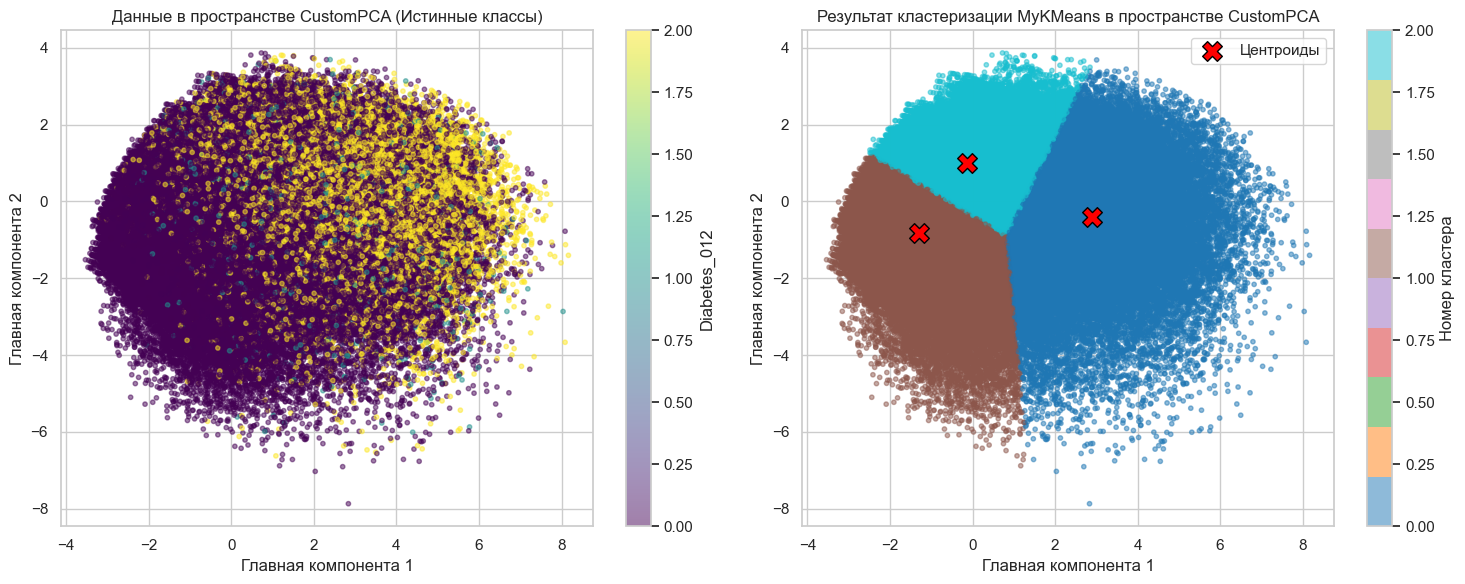

In [15]:
custom_pca = CustomPCA(n_components=2)
X_pca = custom_pca.fit_transform(X_cl_scaled)
print(f'Доли объяснённой дисперсии первых 2 главных компонент: {custom_pca.explained_variance_ratio_.round(4)}')

kmeans = MyKMeans(n_clusters=3, random_state=RANDOM_STATE).fit(X_pca)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 6))

scatter1 = ax1.scatter(X_pca[:, 0], X_pca[:, 1], c=y_cl, cmap='viridis', alpha=0.5, s=10)
ax1.set_title('Данные в пространстве CustomPCA (Истинные классы)')
ax1.set_xlabel('Главная компонента 1')
ax1.set_ylabel('Главная компонента 2')
fig.colorbar(scatter1, ax=ax1, label='Diabetes_012')

scatter2 = ax2.scatter(X_pca[:, 0], X_pca[:, 1], c=kmeans.labels_, cmap='tab10', alpha=0.5, s=10)
ax2.scatter(kmeans.centroids[:, 0], kmeans.centroids[:, 1], c='red', marker='X', s=200,
            edgecolors='black', label='Центроиды')
ax2.set_title('Результат кластеризации MyKMeans в пространстве CustomPCA')
ax2.set_xlabel('Главная компонента 1')
ax2.set_ylabel('Главная компонента 2')
ax2.legend()
fig.colorbar(scatter2, ax=ax2, label='Номер кластера')

plt.tight_layout()
plt.show()

## Выводы
1. **Отбор признаков и снижение размерности в задаче регрессии (`Wine Quality`, 12 признаков):** На исходных 12 признаках базовый ансамбль `BaggingRegressor` показал `R2 = 0.4302`, `MAE = 0.4607`. Нелинейное и линейное выделение главных компонент, а также мягкая фильтрация по дисперсии **улучшили качество регрессии** за счёт декорреляции мультиколлинеарных химических показателей (`density`, `alcohol`, `residual sugar`) и подавления шума:
   * **`KernelPCA (sigmoid, 5 компонент)`:** `R2 = 0.4607`, `MAE = 0.4586` (лучший результат);
   * **`PCA (7 компонент)`:** `R2 = 0.4479`, `MAE = 0.4584`;
   * **`VarianceThreshold (10 признаков)`:** `R2 = 0.4322`, `MAE = 0.4613`.
   Напротив, агрессивный отбор 7 исходных признаков методами `RFE (k=7)` (`R2 = 0.4214`, `MAE = 0.4695`) и `SelectKBest (k=7)` (`R2 = 0.3672`, `MAE = 0.4812`) привёл к умеренному снижению $R^2$ из-за отбрасывания информативных физико-химических переменных.
2. **Отбор признаков и снижение размерности в задаче классификации (`Diabetes_012`, 21 признак):** На всех 21 признаках получены `Accuracy = 0.8083`, `F1 (weighted) = 0.7792`, `F1 (macro) = 0.3881`. Сжатие признакового пространства почти вдвое не только не ухудшило, но и слегка повысило целевые метрики:
   * **`PCA (12 компонент)`** увеличил точность до **`Accuracy = 0.8139`** (`F1 (weighted) = 0.7796`, `F1 (macro) = 0.3848`);
   * **`VarianceThreshold (19 признаков)`** достиг **`F1 (weighted) = 0.7805`** (`Accuracy = 0.8083`, `F1 (macro) = 0.3928`);
   * **`RFE (k=12)`** показал лучший макро-усреднённый результат **`F1 (macro) = 0.3983`** (`Accuracy = 0.8032`, `F1 (weighted) = 0.7797`), опередив `SelectKBest (k=12)` (`Accuracy = 0.8006`, `F1 (weighted) = 0.7775`, `F1 (macro) = 0.3933`).
3. **Линейные vs нелинейные методы:** Линейный `PCA` и методы отбора признаков (`VarianceThreshold`, `RFE`) обеспечили наилучший баланс сжатия и точности на обеих задачах, тогда как методы вложения в сверхнизкую размерность `Isomap (5)`, `UMAP (5)` и `t-SNE (3)` сильнее теряют разделяющую информацию (`Accuracy = 0.7978`, `0.7700` и `0.7511` в классификации; `R2 = 0.3560`, `0.3535` и `0.4134` в регрессии) и наиболее эффективны именно для 2D/3D визуализации структуры данных.
4. **Собственная реализация `CustomPCA`:** Построенная на спектральном разложении ковариационной матрицы реализация полностью совпадает с `sklearn.decomposition.PCA` (первые две главные компоненты объясняют `16.84 %` и `8.35 %` дисперсии соответственно) и позволяет наглядно визуализировать разбиение 21-мерной выборки на кластеры алгоритмом `MyKMeans`.